Olá!

Meu nome é **Laura** e serei a revisora do seu projeto hoje.

Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você possa encontrá-lo e corrigi-lo. Ao longo do notebook também farei observações de melhoria e comentários sobre suas análises — meu objetivo é prepará-lo(a) para trabalhar como **Data Analyst** no mercado real.

Se não conseguir identificar o erro, na próxima iteração darei uma dica mais precisa com exemplos práticos. Estou aberta a feedbacks e discussões.

**Por favor, não mova, modifique ou exclua meus comentários.**

Você encontrará meus comentários em caixas coloridas:

<div class="alert alert-block alert-success"><b>Comentário da revisora (Laura):</b> <a class="tocSkip"></a>Sucesso. Tudo foi feito corretamente.</div>

<div class="alert alert-block alert-warning"><b>Comentário da revisora (Laura):</b> <a class="tocSkip"></a>Atenção. Sugestão ou observação de melhoria.</div>

<div class="alert alert-block alert-danger"><b>Comentário da revisora (Laura):</b> <a class="tocSkip"></a>Precisa de correção. O projeto não pode ser aceito com comentários em vermelho abertos.</div>

Você pode me responder usando:

<div class="alert alert-block alert-info"><b>Resposta da Aluna.</b> <a class="tocSkip"></a></div>

<div class="alert alert-block alert-success">
<b>Status do projeto: Aprovado 🎉</b> <a class="tocSkip"></a>

Olá, Cauê! Excelente entrega — conferi os números de cada etapa contra os outputs (duplicados, valores ausentes, limite de 64 itens no carrinho) e tudo bate com o que você escreveu nas conclusões. Fiz todas as 5 perguntas da Etapa C mesmo precisando de só 2, e a análise de recompra por produto/cliente mostra um bom cuidado em não confiar cegamente em porcentagens com baixo volume — ótimo raciocínio crítico. Projeto aprovado!

Deixei só duas observações amarelas nas células correspondentes (título de gráfico copiado e uma conclusão que extrapola um pouco o que o gráfico mostra) — não bloqueiam a aprovação, é só pra você ficar de olho nas próximas entregas.
</div>




# Vamos encher o carrinho!

# Introdução

O Instacart é uma plataforma de entrega de supermercado onde os clientes podem fazer um pedido no supermercado e depois receber sua compra, semelhante ao funcionamento do Uber Eats e do iFood. O conjunto de dados que fornecemos foi modificado a partir do original. Reduzimos o tamanho dele para que seus cálculos sejam executados mais rapidamente e incluímos valores ausentes e duplicados. Também tivemos o cuidado de preservar as distribuições dos dados originais quando fizemos as alterações.

Você precisa completar três etapas. Para cada uma delas, escreva uma breve introdução descrevendo como você pretende concluir a etapa e justifique suas decisões em parágrafos explicativos a medida que você avança na solução. Escreva também uma conclusão para resumir suas conclusões e escolhas.



## Dicionário de dados

Há cinco tabelas no conjunto de dados, e você vai precisar usar todas elas para pré-processar seus dados e fazer AED. Abaixo está um dicionário que lista as colunas de cada tabela e descreve os dados contidos nelas.

- `instacart_orders.csv`: cada linha corresponde a um pedido no aplicativo da Instacart
    - `'order_id'`: é o número que identifica cada pedido de forma exclusiva
    - `'user_id'`: é o número de identificação exclusivo da conta de cada cliente
    - `'order_number'`: é o número de vezes que o cliente fez um pedido
    - `'order_dow'`: é o dia da semana em que o pedido foi feito (0 é domingo)
    - `'order_hour_of_day'`: é a hora do dia em que o pedido foi feito
    - `'days_since_prior_order'`: é o número de dias desde que o cliente fez seu pedido anterior




- `products.csv`: cada linha corresponde a um produto exclusivo que os clientes podem comprar
    - `'product_id'`: é o número de identificação unívoco de cada produto
    - `'product_name'`: é o nome do produto
    - `'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    - `'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado




-	`order_products.csv`: cada linha corresponde a um item incluído em um pedido
    -	`'order_id'`: é o número que identifica cada pedido de forma exclusiva
    -	`'product_id'`: é o número de identificação exclusivo de cada produto
    -	`'add_to_cart_order'`: é a ordem sequencial em que cada item foi colocado no carrinho
    -	`'reordered'`: 0 se o cliente nunca comprou o produto antes, 1 se já o comprou




-	`aisles.csv`
    -	`'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    -	`'aisle'`: é o nome do corredor



-	`departments.csv`
    -	`'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado
    -	`'department'`: é o nome do departamento


# Etapa 1. Visão geral dos dados

Leia os arquivos de dados (/datasets/instacart_orders.csv, /datasets/products.csv, /datasets/aisles.csv, /datasets/departments.csv e /datasets/order_products.csv) com `pd.read_csv()` usando os parâmetros apropriados para fazer isso corretamente. Verifique as informações para cada DataFrame criado.


## Plano de solução

Escreva aqui seu plano para a Etapa 2. Visão geral dos dados

In [1]:
import pandas as pd # Importe as bibliotecas
from matplotlib import pyplot as plt

In [2]:
 # leia os conjuntos de dados em DataFrames
df_instacart_orders = pd.read_csv('/datasets/instacart_orders.csv', sep = ';')
df_products = pd.read_csv('/datasets/products.csv', sep = ';') 
df_aisles = pd.read_csv('/datasets/aisles.csv', sep = ';')
df_departments = pd.read_csv('/datasets/departments.csv', sep = ';')
df_order_products = pd.read_csv('/datasets/order_products.csv', sep = ';') 

In [3]:
df_instacart_orders.info()
print()
print(df_instacart_orders.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
366122   2045566   139974             6          4                  9   
249589   1131475    21750             1          6                 11   
24357    2903723   119021            39          4                  9   
63101     689458    72371             3          1                 16   
200532   1550942    73269            10  

In [4]:
df_products.info()
print()
print(df_products.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB

       product_id                      product_name  aisle_id  department_id
22538       22539  First Bananas Stage 1 4 Months +        92             18
38770       38771                               NaN       100             21
23440       23441     Long Grain Natural Brown Rice        63              9
23020       23021                San Marzano Tomato        81             15
4642         4643    Almond and Shea Butter Shampoo        22             11


In [5]:
df_aisles.info() 
print()
print(df_aisles.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB

     aisle_id                          aisle
55         56                  diapers wipes
123       124                        spirits
114       115  water seltzer sparkling water
7           8                bakery desserts
113       114              cleaning products


In [6]:
df_departments.info()
print()
print(df_departments.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes

    department_id       department
10             11    personal care
19             20             deli
14             15     canned goods
8               9  dry goods pasta
18             19           snacks


In [7]:
df_order_products.info(show_counts=True)
print()
print(df_order_products.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB

         order_id  product_id  add_to_cart_order  reordered
3977837   2331021       35030                4.0          1
2028353   1631189       14104               32.0          1
1058399   3010072       37353                7.0          0
1663618   2038564       49605                4.0          1
3142283   1872354       46569                7.0          0


## Conclusões

    - Abri os arquivos no bloco de notas para entender informações como estavam armazenados, percebi que o separador em todas as colunas é ';', por isso adicionamos o parâmetro 'sep='.
    - Quando chamamos o método .info() verificamos também que alguns dados como order_id e product_id estão como o tipo numérico e por isso necessitarão de tratamento mais a frente para serem transformados em object, que é o tipo mais adequado nessa situação de valores para identificação.
    - No df_order_products como há muitas linhas usamos como parâmetro do .info o show_counts=True que mostra os valores não nulos naquele DataFrame.
    - Chamamos também o método sample para termos uma amostra de como os dados estão nas células, assim conseguimos ter uma ideia melhor de como estão os dados ao invés de abrir arquivo por arquivo.
    - No começo da análise sempre é ideal chamarmos o info() e o sample() para termos uma ideia melhor do que nos espera.

# Etapa 2. Preparação de dados

Faça o pré-processamento dos dados da seguinte maneira:

-	Verifique e corrija os tipos de dados (por exemplo, certifique-se de que as colunas de ID sejam números inteiros)
-	Identifique e preencha valores ausentes
-	Identifique e remova valores duplicados

Certifique-se de explicar que tipos de valores ausentes e duplicados você encontrou, como você os preencheu ou removeu, por que escolheu esses métodos e por que você acha que esses valores ausentes e duplicados estavam presentes no conjunto de dados.

## Plano de solução

    - Na segunda etapa irei trabalhar com o que eu vi nos módulos 2 e 5 do sprint 3, verificar valores ausentes e duplicados e corrigí-los, e verificar os tipos de dados que precisam de conversão, como os números que precisam ser convertidos para string e verificando se alguns float numbers podem ser convertidos para inteiros usando o método .array_equal().

## Encontre e remova valores duplicados (e descreva por que você está fazendo suas escolhas)

### DataFrame `instacart_orders`

In [8]:
print(df_instacart_orders.duplicated().sum())

15


Há linhas duplicadas? Se sim, o que elas têm em comum?

In [9]:


print(df_instacart_orders[(df_instacart_orders['order_hour_of_day'] == 2) & (df_instacart_orders['order_dow'] == 3)])
print()
print(df_instacart_orders[(df_instacart_orders['order_hour_of_day'] == 2) & (df_instacart_orders['order_dow'] == 3)].duplicated().sum())
# verifique todos os pedidos feitos às 2h da manhã nas quartas-feiras



        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

- Verifiquei que há 121 pedidos feitos em uma quarta feira às 2h da manhã, o que é um horário atípico para tantos pedidos, e isso já levanta uma suspeita. Investigando, percebi todos os pedidos duplicados que encontramos anteriormente estão sendo feitos às 2 horas da manhã de quarta feira, confirmei essa duplicação pela linha de código onde usamos o método .duplicated().sum().

In [10]:
df_instacart_orders = df_instacart_orders.drop_duplicates().reset_index(drop=True) # Remova pedidos duplicados

In [11]:
print(df_instacart_orders.duplicated().sum()) # Verifique as linhas duplicadas mais uma vez

0


In [12]:
print(df_instacart_orders.duplicated(subset='order_id').sum()) # Verifique novamente apenas os IDs de pedidos duplicados
print()
print(df_instacart_orders['order_id'].value_counts())

0

1048576    1
3389216    1
1100604    1
1275704    1
2337103    1
          ..
1752059    1
2794488    1
711671     1
1711087    1
2047       1
Name: order_id, Length: 478952, dtype: int64


Descreva brevemente suas conclusões e o que você fez com elas.

- Apliquei o drop_duplicates e reset_index para que o índice não fique incorreto. verifiquei que de fato os duplicados desapareceram usando o método value_counts e suplicated(subset='order_id').sum.
- Ainda é estranho haverem tantos pedidos em uma madrugada de quarta feira, porém pode ter havido algum bug no sistema, ou muitas pessoas estavam com vontade de fazer uma boquinha da madrugada ao mesmo tempo.

### DataFrame `products`

In [13]:
print(df_products.duplicated().sum()) # Verifique se há linhas completamente duplicadas

0


In [14]:
print(df_products['product_id'].duplicated().sum()) # Verifique apenas IDs dos produtos duplicados

0


In [15]:
df_products['product_name'] = df_products['product_name'].str.lower()
print(df_products['product_name'].duplicated().sum()) # Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)

1361


In [16]:
print(df_products['product_name'].dropna().duplicated().sum())  # Verifique os nomes de produtos duplicados que não estão faltando

print()

print(df_products[df_products['product_name'].duplicated(keep=False)][['product_id', 'product_name']].sort_values('product_name'))

104

       product_id                               product_name
23339       23340  18-in-1 hemp peppermint pure-castile soap
31844       31845  18-in-1 hemp peppermint pure-castile soap
19941       19942            aged balsamic vinegar of modena
13152       13153            aged balsamic vinegar of modena
24830       24831         albacore solid white tuna in water
...           ...                                        ...
49552       49553                                        NaN
49574       49575                                        NaN
49640       49641                                        NaN
49663       49664                                        NaN
49668       49669                                        NaN

[1465 rows x 2 columns]


Descreva brevemente suas conclusões e o que você fez com elas.
- Identificamos um problema de cadastro, usamos o parâmetro 'Keep= False' para não perdermos nenhuma ocorrência de duplicação, já que o padrão do pandas oculta a primeira duplicata.
- Verifiquei que há os mesmos produtos registrados em mais de um código, pois antes os caracteres dos nomes dos produtos não estavam padronizados, isso irá comprometer a contagem correta de produtos gerando inconsistência na análise.
- Apliquei o 'sort_values' na coluna 'product_name' para que pudessemos ver os nomes que estão duplicados, não os códigos, assim posso ser mais transparente na análise.

### DataFrame `departments`

In [17]:
print(df_departments.duplicated().sum()) # Verifique se há linhas completamente duplicadas

0


In [18]:
print(df_departments['department_id'].duplicated().sum()) # Verifique apenas IDs duplicados de departamentos

0


Descreva brevemente suas conclusões e o que você fez com elas.
- Neste documento não há problemas de arquivos duplicados.

### DataFrame `aisles`

In [19]:
print(df_aisles.duplicated().sum()) # Verifique se há linhas completamente duplicadas

0


In [20]:
print(df_aisles['aisle_id'].duplicated().sum()) # Verifique apenas IDs duplicados de corredores

0


Descreva brevemente suas conclusões e o que você fez com elas.

### DataFrame `order_products`

In [21]:
print(df_order_products.duplicated().sum()) # Verifique se há linhas completamente duplicadas

0


In [22]:
print(df_order_products['order_id'].duplicated().sum()) # Verifique mais uma vez se há outros casos complicados de duplicados
print(df_order_products['product_id'].duplicated().sum())

4094961
4499434


- Apesar de haver duplicados singulares nas colunas 'order_id' e 'product_id' não hpa problema, pois pode ser que em um pedido haja mais produtos, ou que um produto tenha sido solicitado em diferentes pedidos.

## Encontre e remova valores ausentes


Ao processarmos valores duplicados, observamos que também temos valores ausentes que precisamos investigar nas seguintes colunas:

*	A coluna `'product_name'` da tabela products.
*	A coluna `'days_since_prior_order'` da tabela orders.
*	A coluna `'add_to_cart_order'` da tabela order_products.


### DataFrame `products`

In [23]:
print(df_products[df_products['product_name'].isna()]) # Encontre valores ausentes na coluna 'product_name'

       product_id product_name  aisle_id  department_id
37             38          NaN       100             21
71             72          NaN       100             21
109           110          NaN       100             21
296           297          NaN       100             21
416           417          NaN       100             21
...           ...          ...       ...            ...
49552       49553          NaN       100             21
49574       49575          NaN       100             21
49640       49641          NaN       100             21
49663       49664          NaN       100             21
49668       49669          NaN       100             21

[1258 rows x 4 columns]


- Identifiquei 1258 produtos ausentes na base de dados, o que pode comprometer o resultado de futuras análises que dependam desta informação.

In [24]:
print(df_products['aisle_id'].value_counts()) # Todos os nomes de produtos ausentes estão associados com o corredor de ID 100?


100    1258
45     1246
37     1091
47     1038
120    1026
       ... 
113      47
82       44
32       32
68       26
18       12
Name: aisle_id, Length: 134, dtype: int64


- Sim, todos os produtos ausentes estão associados ao corredor 100, podemos ver que a quantidade de produtos ausentes do código anterior bate com a quantidade de vezes que o corredor 100 aparece.

In [25]:
print(df_products['department_id'].value_counts())# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?

11    6564
19    6264
13    5372
7     4366
1     4008
16    3449
17    3085
15    2092
9     1858
4     1684
3     1516
20    1322
21    1258
6     1139
14    1117
18    1081
5     1054
8      972
12     907
2      548
10      38
Name: department_id, dtype: int64


- Sim, todos os produtos ausentes estão associados ao departamento 21, podemos ver que mais uma vez a quantidade de produtos ausentes do código anterior bate com a quantidade de vezes que o departamento 21 aparece.

In [26]:
print(df_aisles.query('aisle_id == 100')[['aisle_id','aisle']]) # Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.
print()
print(df_departments.query('department_id == 21')[['department_id','department']])

    aisle_id    aisle
99       100  missing

    department_id department
20             21    missing


- Verifiquei que em ambas bases de dados, tanto corredor quanto departamento estão como 'missing', ou seja, não há informação relacionado a esse corredor e departamento na base de dados.

In [27]:
df_products['product_name'] = df_products['product_name'].fillna('Unknown')# Preencha nomes de produtos ausentes com 'Unknown'
print(df_products['product_name'].value_counts())

Unknown                                                                  1258
green tea with ginseng and honey                                            3
herring in wine sauce                                                       2
cauliflower head                                                            2
bag of organic lemons                                                       2
                                                                         ... 
condensed chicken noodle soup                                               1
total advanced clean anticavity fluoride and antigingivitistoothpaste       1
vegan meat loaf                                                             1
foil sheets                                                                 1
tulsi peppermint infusion bags - 18 ct                                      1
Name: product_name, Length: 48333, dtype: int64


- Agora que temos os registros como 'unknown' ao invés de nulos podemos fazer uma análise mais assertiva, pois agora temos visibilidade e rastreabilidade, evitando que estes valores sejam ignorados ou que as contagens e agrupamentos sejam distorcidos.

### DataFrame `instacart_orders`

In [28]:
print(df_instacart_orders.isna().sum())# Encontre os valores ausentes

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64


In [29]:
print(df_instacart_orders.query('order_number != 1').isna().sum())
# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?

order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64


- Identifiquei que todos os pedidos que estão ausentes são os primeiros pedidos, e por todos os valores serem legítimos não gera inconsistência em nossa análise.

### DataFrame `order_products`

In [30]:
print(df_order_products.isna().sum()) # Encontre os valores ausentes

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


In [31]:
print(df_order_products['add_to_cart_order'].min())# Quais são os valores mínimo e máximo dessa coluna?
print(df_order_products['add_to_cart_order'].max())

1.0
64.0


In [32]:
cart_order_na = df_order_products[df_order_products['add_to_cart_order'].isna()]['order_id'] # Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'
print(cart_order_na)

737        2449164
9926       1968313
14394      2926893
16418      1717990
30114      1959075
            ...   
4505662    1800005
4511400    1633337
4517562     404157
4534112    1673227
4535739    1832957
Name: order_id, Length: 836, dtype: int64


In [33]:
# Todos os pedidos com valores ausentes contêm mais de 64 produtos?
# Agrupe os pedidos com dados ausentes por ID de pedido
# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem
product_na = df_order_products[df_order_products['order_id'].isin(cart_order_na)].groupby('order_id')['product_id'].count()
print(product_na.min())

65


- Podemos ver que a partiir de 65 produtos há uma limitação do sistema em registrar a posição de itens além do 64º.

In [34]:

 # Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype('int')

print(df_order_products.info(show_counts=True))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           4545007 non-null  int64
 1   product_id         4545007 non-null  int64
 2   add_to_cart_order  4545007 non-null  int64
 3   reordered          4545007 non-null  int64
dtypes: int64(4)
memory usage: 138.7 MB
None


-  converti a coluna `add_to_cart_order` para o tipo inteiro após preencher os valores ausentes com 999, um valor fora do padrão real que funciona como sinalizador para identificar facilmente esses registros em análises futuras.

## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 2. Preparação de dados

Durante a preparação dos dados percebi algumas inconsistências:
- 1º produtos com nomes ausentes na tabela de produtos, que preenchemos como "unknown" para mantê-los rastreáveis.
- 2º há uma limitação do sistema que impede o registro da posição no carrinho para pedidos com mais de sessenta e quatro produtos, resolvida ao preencher esses casos com o valor 999.
- 3º valores ausentes na coluna de dias desde o pedido anterior, que na verdade não representam um erro, e sim o comportamento esperado para o primeiro pedido de cada cliente, que naturalmente não tem um pedido anterior pra comparar.

# Etapa 3. Análise de dados

Quando os dados estiverem processados ​​e prontos, execute a seguinte análise:

# [A] Fácil (é necessário concluir tudo para passar)

1.	Verifique se os valores nas colunas `'order_hour_of_day'` e `'order_dow'` na tabela `orders` fazem sentido (ou seja, os valores da coluna  `'order_hour_of_day'` variam de 0 a 23 e os da `'order_dow'` variam de 0 a 6).
2.	Crie um gráfico que mostre quantas pessoas fazem pedidos a cada hora do dia.
3.	Crie um gráfico que mostre em que dia da semana as pessoas fazem compras.
4.	Crie um gráfico que mostre quanto tempo as pessoas esperam até fazer seu próximo pedido e comente sobre os valores mínimo e máximo.


### [A1] Verifique se os valores fazem sentido

In [35]:
print(df_instacart_orders['order_hour_of_day'].min())
print(df_instacart_orders['order_hour_of_day'].max())

0
23


In [36]:
print(df_instacart_orders['order_dow'].min())
print(df_instacart_orders['order_dow'].max())

0
6


- Não há problemas nessas colunas, como visto acima estão de acordo com o esperado.

### [A2] Quantas pessoas fazem pedidos a cada hora do dia?

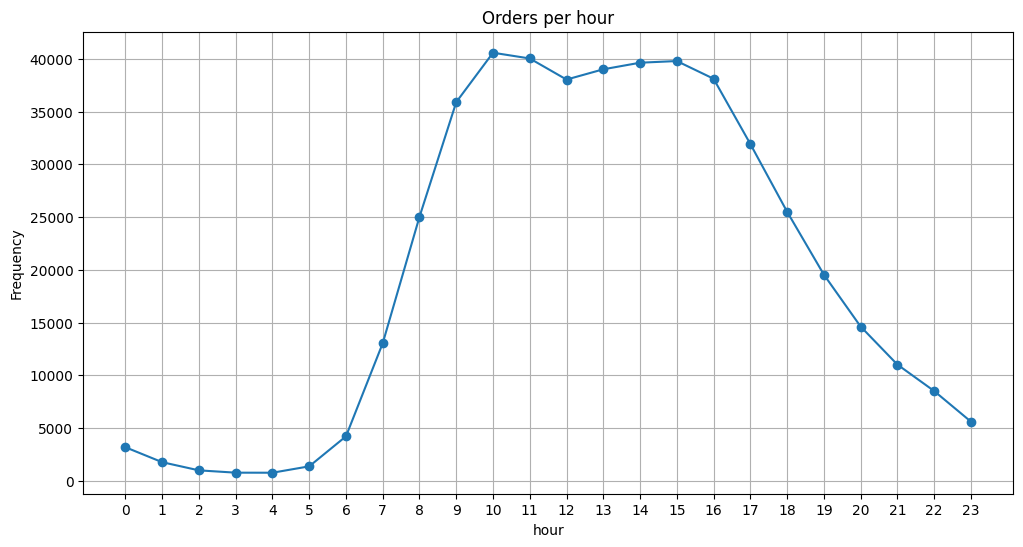

In [37]:



df_instacart_orders['order_hour_of_day'].value_counts().sort_index().plot(title= 'Orders per hour',
                                             ylabel= 'Frequency',
                                             xlabel= 'hour',
                                             grid= True,
                                             legend= False,
                                             kind= 'line',
                                             figsize=(12,6),
                                             style= 'o-',
                                             xticks=range(0,24,1))
plt.show()



- O horário de pico dos pedidos é às 10h, e continua em alta até às 15h, quando o volume de pedidos feitos começa a abaixar. Vemos que o vale é no horário da madrugada (ainda sim, muitos pedidos são feitos às 2h da manhhã, boquinha da madrugada). 

### [A3] Em que dia da semana as pessoas compram produtos alimentícios?

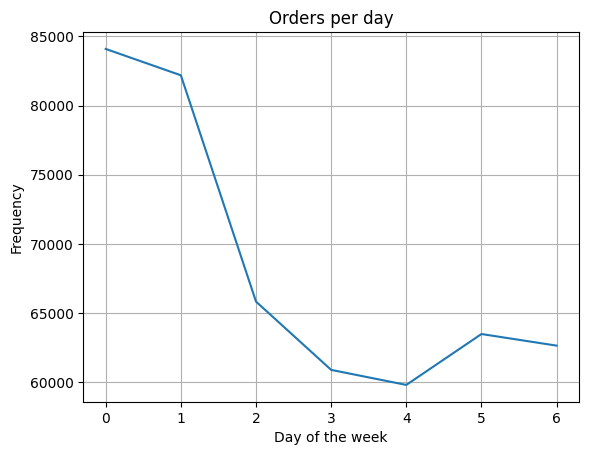

In [38]:
df_instacart_orders['order_dow'].value_counts().sort_index().plot(title= 'Orders per day',
                                             ylabel= 'Frequency',
                                             xlabel= 'Day of the week',
                                             grid= True,
                                             legend= False,
                                             kind= 'line' )
plt.show()


- É possível verificar que a maioria dos pedidos é feito no domingo e o vale é na quinta feira.

### [A4] Quanto tempo as pessoas esperam até fazer outro pedido?

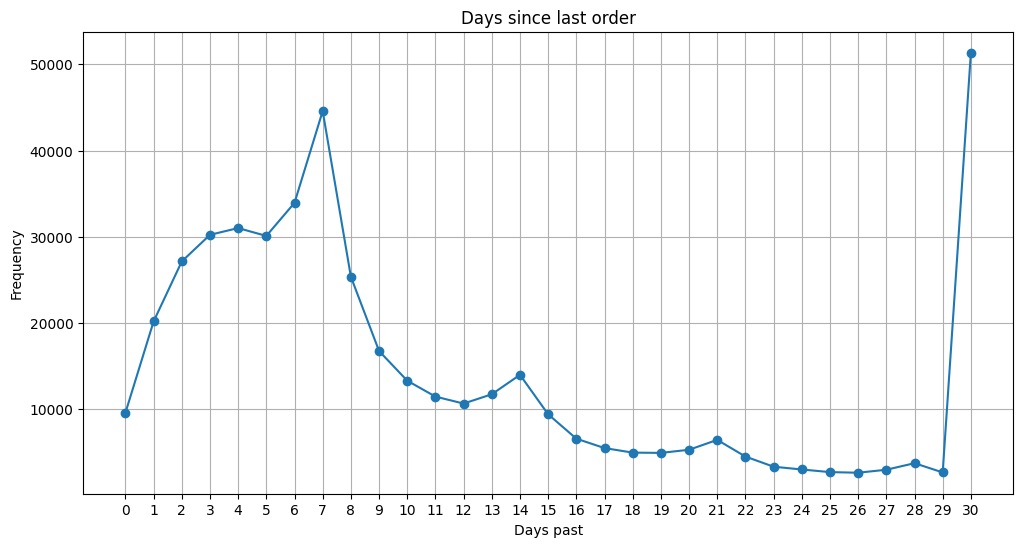

In [39]:

df_instacart_orders['days_since_prior_order'].value_counts().sort_index().plot(title= 'Days since last order',
                                             ylabel= 'Frequency',
                                             xlabel= 'Days past',
                                             grid= True,
                                             legend= False,
                                             kind= 'line',
                                             style= 'o-',
                                             figsize=(12,6),
                                            xticks=range(0,31,1))
plt.show()


- Podemos ver dois picos: Os compradores semanais (no 7) e dos compradores mensais (no 30). Por outro lado vemos que o vale está cada vez mais próximo do período entre 25 a 29 dias.
- Verifica-se que há uma discrepância grande entre o vale e o pico (dia 29 e dia 30) essa discrepância pode ser explicada por duas hipóteses: A primeira é que muitos usuários fazem compras mensais recorrentes, concentrando pedidos justamente no dia trinta. A segunda é que o sistema pode ter um limite de registro em trinta dias, agrupando todos os clientes que ficaram mais tempo do que isso sem comprar, o que pode infla artificialmente esse valor e pode comprometer a transparência da análise. 

# [B] Médio (é necessário concluir tudo para passar)

1.	Há alguma diferença nas distribuições de `'order_hour_of_day'` nas quartas e sábados? Construa gráficos de barras para ambos os dias no mesmo gráfico e descreva as diferenças que você notou.
2.	Construa um gráfico de distribuição para o número de pedidos que os clientes fazem (ou seja, quantos clientes fizeram apenas 1 pedido, quantos fizeram apenas 2, quantos apenas 3, etc.)
3.	Quais são os 20 produtos comprados com mais frequência? Exiba os IDs e nomes.


### [B1] Diferenças nas quartas e sábados em `'order_hour_of_day'`. Crie gráficos de barras para ambos os dias e descreva as diferenças.

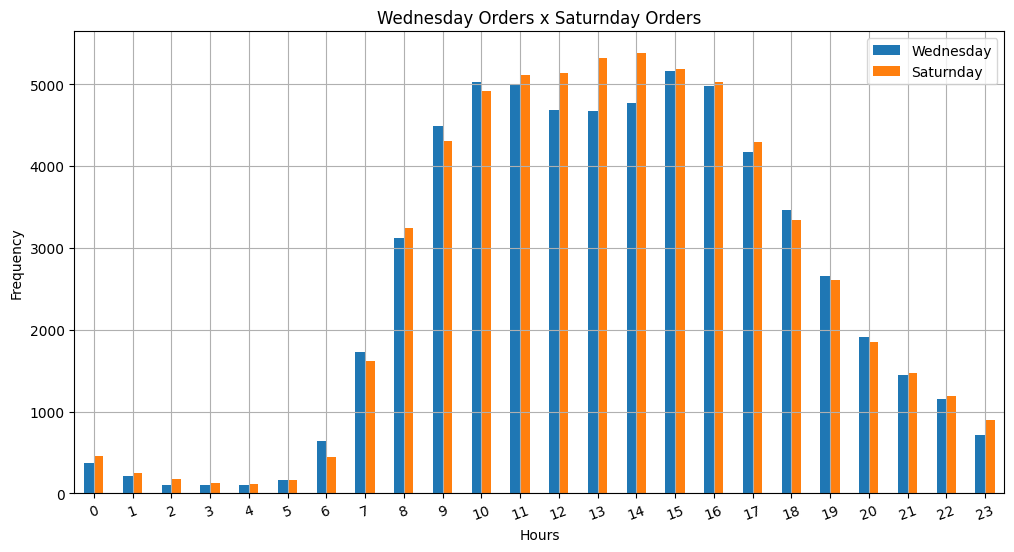

In [40]:

wn_order_hour = df_instacart_orders.query('order_dow == 3')['order_hour_of_day'].value_counts().sort_index()
st_order_hour = df_instacart_orders.query('order_dow == 6')['order_hour_of_day'].value_counts().sort_index()

orders_by_hour = pd.DataFrame({
    'Wednesday': wn_order_hour,
    'Saturday': st_order_hour
})

orders_by_hour.plot(kind= 'bar', figsize=(12, 6), title= 'Wednesday Orders x Saturnday Orders', ylabel= 'Frequency', xlabel= 'Hours', rot=20, grid= True )

plt.legend(['Wednesday','Saturnday'])

plt.show()

- É possível verificar que o pico e o vale de ambos é bem parecida,porém aos sábados o pico é às 14h enquanto às quartas o pico é às 15h, mas ainda sim menor que a quantidade de pedidos no sábado neste mesmo horário. É possível verificar também que o sábado supera os pedidos da quarta feira em 15 horários diferentes.

### [B2] Qual é a distribuição do número de pedidos por cliente?

In [41]:
# Quantidade de pedidos feita por cada cliente(“quantos pedidos cada cliente fez”)
orders_per_client = df_instacart_orders['user_id'].value_counts()

# Quantidade de clientes para cada número de pedidos(“quantos clientes fizeram 1, 2, 3... pedidos”)
client_distribution = orders_per_client.value_counts().sort_index()


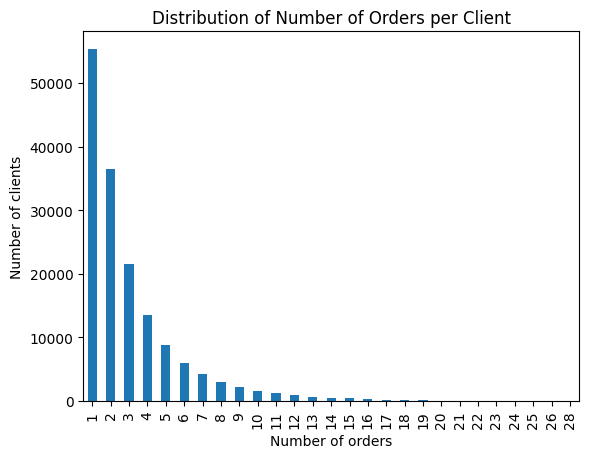

In [42]:
client_distribution.plot(
    kind='bar',
    title='Distribution of Number of Orders per Client',
    xlabel='Number of orders',
    ylabel='Number of clients'
)

plt.show()

<div class="alert alert-block alert-warning">
<b>Comentário — Conclusão sobre popularidade: </b> <a class="tocSkip"></a>

A distribuição de pedidos por cliente é uma "foto" do comportamento acumulado, não mede variação ao longo do tempo — então não dá pra concluir que "a plataforma não está com popularidade crescente" só com esse gráfico (isso exigiria olhar pedidos por período, por exemplo). Vale reformular essa frase para focar no que o gráfico realmente mostra: que a maioria dos clientes é pouco recorrente.
</div>

- A maioria dos clientes fez somente um pedido, mais que o dobro dos que fizeram 3. Vendo isso conclui-se que a plataforma não está com popularidade crescente, uma vez que o gráfico praticamente some depois dos clientes que fizeram 19 pedidos.

### [B3] Quais são os 20 produtos mais populares? Exiba os IDs e nomes.

In [43]:
product_count = df_order_products['product_id'].value_counts()

# transformei a Series 'product_count' em DataFrame pra poder fazer o merge
df_product_count = product_count.reset_index()
df_product_count.columns = ['product_id', 'product_count']

In [44]:
# junta com df_products pra trazer o nome
df_merged = df_product_count.merge(df_products, on='product_id')

In [45]:
df_merged = df_merged.sort_values('product_count', ascending=False) #Apesar de o value_counts já colocar em ordem decrescente a coluna 'product_count', temos que ter certeza que não há problema de contagem.
print(df_merged[['product_id', 'product_name']].head(20))

    product_id              product_name
0        24852                    banana
1        13176    bag of organic bananas
2        21137      organic strawberries
3        21903      organic baby spinach
4        47209      organic hass avocado
5        47766           organic avocado
6        47626               large lemon
7        16797              strawberries
8        26209                     limes
9        27845        organic whole milk
10       27966       organic raspberries
11       22935      organic yellow onion
12       24964            organic garlic
13       45007          organic zucchini
14       39275       organic blueberries
15       49683            cucumber kirby
16       28204        organic fuji apple
17        5876             organic lemon
18        8277  apple honeycrisp organic
19       40706    organic grape tomatoes


- Podemos ver que os produtos mais saudáveis são frutas e produtos frescos. Juntando as 3 ideias isso sugere que o perfil de usuários é de pessoas que procuram uma alimentação mais saudável. Esse comportamento se concentra do final da manhã para o início da tarde, tanto durante a semana quanto no final de semana, porém é um hábito pouco recorrente, visto que a maioria dos clientes compraram poucas ou apenas uma vez na plataforma.

# [C] Difícil (é necessário concluir pelo menos duas perguntas para passar)

1.	Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?
2.	Quais são os 20 principais itens incluídos mais frequentemente em pedidos repetidos? Exiba os IDs e nomes.
3.	Para cada produto, qual parcela de seus pedidos são repetidos? Crie uma tabela com colunas de ID e nome do produto e a proporção de pedidos repetidos.
4.	Para cada cliente, qual proporção de todos os seus pedidos são repetidos?
5.	Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros? Exiba o ID do produto, nome e o número de vezes que ele foi o primeiro a ser adicionado a um carrinho.


### [C1] Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?

In [46]:
order_count = df_order_products.groupby('order_id').count()['product_id'].value_counts().sort_index() #Quantos 'Product_id' tem esse 'order_id'?

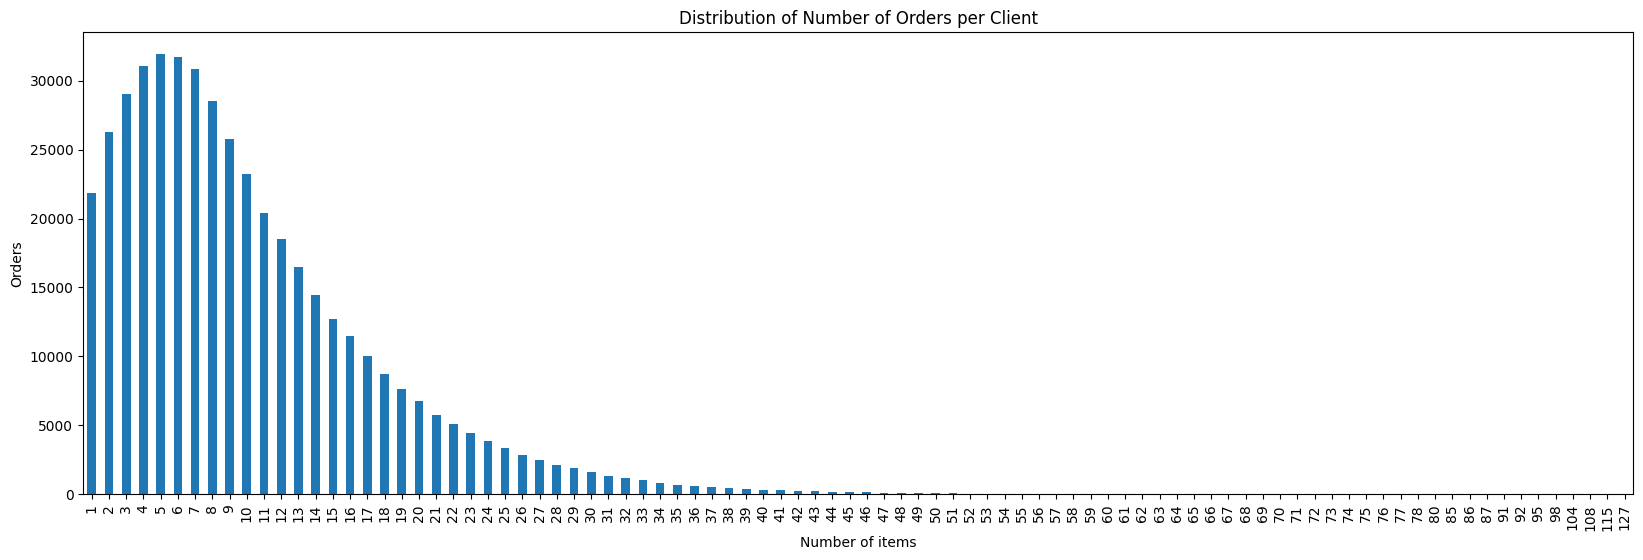

In [47]:
order_count.plot(
    kind='bar',
    title='Distribution of Number of Orders per Client',
    xlabel='Number of items',
    ylabel='Orders',
    figsize= (20,6)
)
plt.show()

- Verificamos no gráfico que os clientes geralmente compram de 4 a 7 itens por vez.

### [C2] Quais são os 20 principais itens incluídos com mais frequência em pedidos repetidos? Exiba os IDs e nomes.

In [48]:
# Estamos filtranddo apenas os produtos que foram recomprados.
product_count = df_order_products.query('reordered == 1')['product_id'].value_counts()

In [49]:
df_product_count = product_count.reset_index()
df_product_count.columns = ['product_id', 'product_count']
print(df_product_count.head())

   product_id  product_count
0       24852          55763
1       13176          44450
2       21137          28639
3       21903          26233
4       47209          23629


In [50]:
df_merged = df_product_count.merge(df_products, on='product_id')

In [51]:
# Organizei os produtos para que pudessemos ter o nosso top 20, de maior para o menor.
df_merged = df_merged.sort_values('product_count', ascending=False)
print(df_merged[['product_id', 'product_name']].head(20))

    product_id              product_name
0        24852                    banana
1        13176    bag of organic bananas
2        21137      organic strawberries
3        21903      organic baby spinach
4        47209      organic hass avocado
5        47766           organic avocado
6        27845        organic whole milk
7        47626               large lemon
8        27966       organic raspberries
9        16797              strawberries
10       26209                     limes
11       22935      organic yellow onion
12       24964            organic garlic
13       45007          organic zucchini
14       49683            cucumber kirby
15       28204        organic fuji apple
16        8277  apple honeycrisp organic
17       39275       organic blueberries
18        5876             organic lemon
19       49235       organic half & half


- Podemos ver que os itens mais recomprados são praticamente os mesmos que aparecem no top vinte de produtos mais populares, pois são itens recorrentes que fazem parte do consumo básico dos clientes.

### [C3] Para cada produto, qual parcela de todos os pedidos dele são repetidos?

In [52]:
# Separamos os pedidos repetidos e total de pedidos em variáveis.
reorder_count = df_order_products.query('reordered == 1')['product_id'].value_counts()
total_count = df_order_products['product_id'].value_counts()

# Renomeamos a coluna product_id que será mesclada.
reorder_count.index.name = 'product_id'
total_count.index.name = 'product_id'

df_reorder_share = pd.DataFrame({
'reorder_count': reorder_count,
'total_count': total_count
})

df_reorder_share['reorder_share'] = df_reorder_share['reorder_count'] / df_reorder_share['total_count']

df_reorder_share = df_reorder_share.reset_index()
df_reorder_share = df_reorder_share.dropna(subset=['reorder_share'])

df_reorder_share = df_reorder_share.merge(df_products, on='product_id', how='inner')

# Reordenei os valores para que pudéssemos ter uma melhor análise.
df_reorder_share = df_reorder_share.sort_values('reorder_share', ascending=False)

print(df_reorder_share[['product_id', 'product_name', 'reorder_share']])

       product_id                                       product_name  \
8682        12038           for women maximum absorbency l underwear   
1283         1809  slow kettle style santa fe chicken enchilada s...   
26334       36122                                  spicy chili beans   
2306         3205            original pure chocolate whippet cookies   
30526       41901   moisturizing lotionized shave gel with vitamin e   
...           ...                                                ...   
34536       47385                                     ground mustard   
27061       37120                                          dill weed   
10643       14688                                     bamboo skewers   
20937       28741                              organic ground cloves   
32506       44626                                    ground allspice   

       reorder_share  
8682        1.000000  
1283        1.000000  
26334       1.000000  
2306        1.000000  
30526       1.000000

- Vemos que os produtos comprados são produtos de nicho, como itens de higiene ou produtos de alimentação especiais, como tempero. Porém, são itens pouco comprados no geral, então qualquer recompra já representa uma fração grande do total, o que infla artificialmente a porcentagem de recompra.

### [C4] Para cada cliente, qual proporção de todos os seus pedidos são repetidos?

In [53]:
#Aqui mesclamos os pedidos feitos por clientes com os produtos que estão nos pedidos, e depois contamos o total de itens por cliente.
df_merged_orders = df_order_products.merge(df_instacart_orders[['order_id', 'user_id']], on='order_id')
total_items = df_merged_orders.groupby('user_id')['product_id'].count()

In [54]:
reorder_items = df_merged_orders[df_merged_orders['reordered'] == 1].groupby('user_id')['product_id'].count()

In [55]:
df_client_share = pd.DataFrame({
    'total_items': total_items,
    'reorder_items': reorder_items
})

In [56]:
# calculamos a proporcao de itens recomprados por cliente.
df_client_share['reorder_share'] = df_client_share['reorder_items'] / df_client_share['total_items']

df_client_share = df_client_share.sort_values('reorder_share', ascending=False)

print(df_client_share.dropna().reset_index())

        user_id  total_items  reorder_items  reorder_share
0         77195            3            3.0       1.000000
1         74382            5            5.0       1.000000
2         65083            4            4.0       1.000000
3         56239            1            1.0       1.000000
4        203877           11           11.0       1.000000
...         ...          ...            ...            ...
132986     7349           55            1.0       0.018182
132987    57630           57            1.0       0.017544
132988   155522           58            1.0       0.017241
132989   201663           66            1.0       0.015152
132990   106148           67            1.0       0.014925

[132991 rows x 4 columns]


- Os clientes com taxa de recompra mais alta, perto de cem por cento, geralmente são os que fizeram poucos pedidos no total, então esses valores extremos tendem a vir de baixo volume, não necessariamente de fidelidade real. Isso sugere que pra confiar na métrica é melhor olhar clientes com volume mínimo de pedidos.

### [C5] Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros?

In [57]:
#Questão bem parecida com as questões B3 e C1, porém pegando os 
first_product_count = df_order_products.query('add_to_cart_order == 1')['product_id'].value_counts()
df_product_count = first_product_count.reset_index()
df_product_count.columns = ['product_id', 'product_count']

In [58]:
fchoice_products = df_product_count.merge(df_products, on='product_id') 

In [59]:
fchoice_products= fchoice_products.sort_values('product_count', ascending=False)
print(fchoice_products[['product_id', 'product_name']].head(20))

    product_id                 product_name
0        24852                       banana
1        13176       bag of organic bananas
2        27845           organic whole milk
3        21137         organic strawberries
4        47209         organic hass avocado
5        21903         organic baby spinach
6        47766              organic avocado
7        19660                 spring water
8        16797                 strawberries
9        27966          organic raspberries
10       44632   sparkling water grapefruit
11       49235          organic half & half
12       47626                  large lemon
13         196                         soda
14       38689     organic reduced fat milk
15       26209                        limes
16       12341                hass avocados
17        5785  organic reduced fat 2% milk
18       27086                  half & half
19       22935         organic yellow onion


- Os produtos mais populares são geralmente os primeiros a serem escolhidos, isso reforça que os primeiros itens são os básicos e mais familiares antes de o cliente partir pra ver novos itens.

# Conclusão geral do projeto:

Os dados mostram um perfil de compra saudável, com foco em frutas e vegetais frescos, concentrado do final da manhã ao início da tarde, mas um hábito pouco recorrente, já que a maioria dos clientes fez poucos pedidos. Olhando mais de perto, porém, percebemos que métricas de proporção, como taxa de recompra por produto ou por cliente, podem enganar quando calculadas sobre poucos casos, inflando artificialmente porcentagens que parecem altas mas refletem baixo volume. Juntando os dois pontos, a análise sugere um comportamento de compra saudável e pontual pra maioria dos clientes, e reforça que qualquer conclusão baseada em porcentagem, nesse tipo de dado, precisa vir acompanhada do volume por trás dela pra ser confiável.